In [10]:
import gc
import os
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [11]:
df_mental_health = pd.read_csv('project_TM_Mental_health/Text Mining on Mental Health/mental_health.csv')
df_twitter_graph = pd.read_csv('project_TM_Mental_health/Text Mining on Mental Health/twitter_graph.csv')

In [4]:
df_mental_health

,ID,Text,Emotion
0,1,i love getting my rockabilly look on for certa...,Positive
1,2,i love you because i feel safe when you hold m...,Positive
2,3,i wasnt happy about how hon tour cycle ended b...,Positive
3,4,i tried to fix my feelings convinced that how ...,Positive
4,5,i had a blog and i devoted alot of time writin...,Positive
...,...,...,...
42513,67566,The jeongwon da ah bet said kyeorunhaja kyeoru...,Neutral
42514,67567,what genres?,Neutral
42515,67568,davidt 00 virgin again today i m afraid a i m ...,Neutral
42516,67569,me and maddeh are so in sync that both of our ...,Neutral


In [5]:
df_twitter_graph

,Source,Destination,Conversation ID,Relationship Date (UTC),Source Joined Date,Source Followers,Source Followed,Source Verified,Destination Joined Date,Destination Followers,Destination Followed,Destination Verified
0,1.607419e+18,1607418986760750080,1696516719009734740,2023-08-29 13:34:40,2022-12-26 16:55:51,1576.0,2663.0,False,2022-12-26 16:55:51,1576.0,2663.0,False
1,1.607419e+18,1349154719386776064,1697007171974689218,2023-08-31 15:08:03,2022-12-26 16:55:51,1576.0,2663.0,False,NaN,NaN,NaN,NaN
2,8.524955e+07,16106584,1695776470176829882,2023-08-28 12:14:52,2009-10-26 05:58:16,1120.0,2021.0,False,2008-09-03 01:44:04,879658.0,2491.0,False
3,1.678585e+18,15304100,1696139317171622215,2023-08-28 18:56:04,2023-07-11 01:59:49,1.0,48.0,False,2008-07-03 02:07:45,374146.0,20490.0,False
4,2.013468e+08,798639717705272960,1696487752458702960,2023-08-29 11:39:34,2010-10-11 17:06:04,3756.0,1826.0,False,2016-11-15 21:32:01,3140.0,3952.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
548536,1.389410e+18,1389409700178013952,1663541100919812096,2023-05-30 13:41:20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
548537,3.240499e+09,3240498802,1663470569394696198,2023-05-30 09:01:04,2015-05-07 14:15:36,64.0,101.0,False,2015-05-07 14:15:36,64.0,101.0,False
548538,1.552796e+18,1552795969959636992,1663702012423294977,2023-05-31 00:20:44,2022-07-28 23:20:28,2091625.0,1003.0,False,2022-07-28 23:20:28,2091625.0,1003.0,False
548539,1.552796e+18,1552795969959636992,1663654755548233729,2023-05-30 21:12:57,2022-07-28 23:20:28,2091625.0,1003.0,False,2022-07-28 23:20:28,2091625.0,1003.0,False


In [13]:
def dataframe_memory_mb(dataframe):
    """Return the estimated memory usage of a DataFrame in MB."""
    return dataframe.memory_usage(deep=True).sum() / 1024**2


def file_size_mb(path):
    """Return the size of a file in MB."""
    return Path(path).stat().st_size / 1024**2


def timed_call(function, *args, **kwargs):
    """Run a function and return its result and elapsed time in seconds."""
    start = time.perf_counter()
    result = function(*args, **kwargs)
    elapsed = time.perf_counter() - start
    return result, elapsed

In [23]:
print(dataframe_memory_mb(df_mental_health))
print(dataframe_memory_mb(df_twitter_graph))
print(file_size_mb('project_TM_Mental_health/Text Mining on Mental Health/mental_health.csv'))
print(file_size_mb('project_TM_Mental_health/Text Mining on Mental Health/twitter_graph.csv'))

14.024035453796387
169.7903289794922
10.054978370666504
75.06262302398682


In [17]:
DATASET_SIZES = [1_000, 10_000, 100_000, 1_000_000, 5_000_000]

measurement_rows = []

In [18]:
for n_rows in DATASET_SIZES:
    print(f"Generating {n_rows:,} rows...")

    start = time.perf_counter()
    current_df = df_twitter_graph.sample(n=n_rows, replace=True, random_state=42).reset_index(drop=True)
    generation_time = time.perf_counter() - start

    measurement_rows.append({
        "rows": n_rows,
        "columns": current_df.shape[1],
        "generation_time_seconds": generation_time,
        "dataframe_memory_mb": dataframe_memory_mb(current_df)
    })

    print(
        f"Memory: {dataframe_memory_mb(current_df):.2f} MB | "
        f"Generation time: {generation_time:.3f} seconds"
    )

    del current_df
    gc.collect()

Generating 1,000 rows...
Memory: 0.31 MB | Generation time: 0.005 seconds
Generating 10,000 rows...
Memory: 3.09 MB | Generation time: 0.003 seconds
Generating 100,000 rows...
Memory: 30.94 MB | Generation time: 0.022 seconds
Generating 1,000,000 rows...
Memory: 309.52 MB | Generation time: 0.156 seconds
Generating 5,000,000 rows...
Memory: 1547.67 MB | Generation time: 0.731 seconds


In [19]:
size_results = pd.DataFrame(measurement_rows)
size_results

,rows,columns,generation_time_seconds,dataframe_memory_mb
0,1000,12,0.004803,0.308849
1,10000,12,0.003019,3.090107
2,100000,12,0.021738,30.942394
3,1000000,12,0.156030,309.515011
4,5000000,12,0.730534,1547.667858


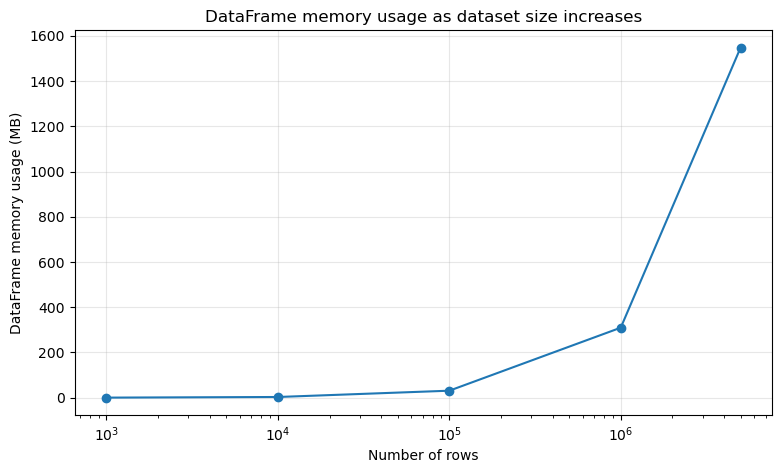

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    size_results["rows"],
    size_results["dataframe_memory_mb"],
    marker="o"
)

plt.xscale("log")
plt.xlabel("Number of rows")
plt.ylabel("DataFrame memory usage (MB)")
plt.title("DataFrame memory usage as dataset size increases")
plt.grid(True, alpha=0.3)
plt.show()